In [4]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
# Load the training dataset

df = pd.read_csv('/content/Book1.csv')

# Display first five rows

df.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,21-06-2020 12:14,2.290000e+15,fraud_Kirlin and Sons,personal_care,2.86,Jeff,Elliott,M,351 Darlene Green,...,33.9659,-80.9355,333497,Mechanical engineer,19-03-1968,2da90c7d74bd46a0caf3777415b3ebd3,1371816865,33.986391,-81.200714,0
1,1,21-06-2020 12:14,3.570000e+15,fraud_Sporer-Keebler,personal_care,29.84,Joanne,Williams,F,3638 Marsh Union,...,40.3207,-110.4360,302,"Sales professional, IT",17-01-1990,324cc204407e99f51b0d6ca0055005e7,1371816873,39.450498,-109.960431,0
2,2,21-06-2020 12:14,3.600000e+15,"fraud_Swaniawski, Nitzsche and Welch",health_fitness,41.28,Ashley,Lopez,F,9333 Valentine Point,...,40.6729,-73.5365,34496,"Librarian, public",21-10-1970,c81755dbbbea9d5c77f094348a7579be,1371816893,40.495810,-74.196111,0
3,3,21-06-2020 12:15,3.590000e+15,fraud_Haley Group,misc_pos,60.05,Brian,Williams,M,32941 Krystal Mill Apt. 552,...,28.5697,-80.8191,54767,Set designer,25-07-1987,2159175b9efe66dc301f149d3d5abf8c,1371816915,28.812398,-80.883061,0
4,4,21-06-2020 12:15,3.530000e+15,fraud_Johnston-Casper,travel,3.19,Nathan,Massey,M,5783 Evan Roads Apt. 465,...,44.2529,-85.0170,1126,Furniture designer,06-07-1955,57ff021bd3f328f8738bb535c302a31b,1371816917,44.959148,-85.884734,0


In [6]:
# Check number of rows and columns

print("Dataset Shape:", df.shape)

# Display column names

print("\nColumn Names:")
print(df.columns)

# Check data types and missing values

print("\nDataset Information:")
df.info()

Dataset Shape: (555719, 23)

Column Names:
Index(['Unnamed: 0', 'trans_date_trans_time', 'cc_num', 'merchant', 'category',
       'amt', 'first', 'last', 'gender', 'street', 'city', 'state', 'zip',
       'lat', 'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time',
       'merch_lat', 'merch_long', 'is_fraud'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 555719 entries, 0 to 555718
Data columns (total 23 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Unnamed: 0             555719 non-null  int64  
 1   trans_date_trans_time  555719 non-null  object 
 2   cc_num                 555719 non-null  float64
 3   merchant               555719 non-null  object 
 4   category               555719 non-null  object 
 5   amt                    555719 non-null  float64
 6   first                  555719 non-null  object 
 7   last                   555719 non-null  obje

In [8]:

# STEP 1: Check dataset dimensions

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Total transactions:", len(df))


Number of rows: 555719
Number of columns: 23
Total transactions: 555719


In [9]:

# STEP 2: Display all column names

print("Available Columns:")

for column in df.columns:
    print(column)


Available Columns:
Unnamed: 0
trans_date_trans_time
cc_num
merchant
category
amt
first
last
gender
street
city
state
zip
lat
long
city_pop
job
dob
trans_num
unix_time
merch_lat
merch_long
is_fraud


In [10]:

# STEP 3: Check data types

print(df.dtypes)


Unnamed: 0                 int64
trans_date_trans_time     object
cc_num                   float64
merchant                  object
category                  object
amt                      float64
first                     object
last                      object
gender                    object
street                    object
city                      object
state                     object
zip                        int64
lat                      float64
long                     float64
city_pop                   int64
job                       object
dob                       object
trans_num                 object
unix_time                  int64
merch_lat                float64
merch_long               float64
is_fraud                   int64
dtype: object


In [11]:

# STEP 4: Check missing values

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nTotal Missing Values:",
      df.isnull().sum().sum())


Missing Values in Each Column:
Unnamed: 0               0
trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
first                    0
last                     0
gender                   0
street                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
trans_num                0
unix_time                0
merch_lat                0
merch_long               0
is_fraud                 0
dtype: int64

Total Missing Values: 0


In [13]:

# STEP 5: Check duplicate transactions

print("Total Duplicate Rows:",
      df.duplicated().sum())

# Check duplicate transaction IDs

print("Duplicate Transaction IDs:",
      df['trans_num'].duplicated().sum())


Total Duplicate Rows: 0
Duplicate Transaction IDs: 0


In [14]:

# STEP 6: Analyse fraud and normal transactions

fraud_counts = df['is_fraud'].value_counts()

print("Transaction Distribution:")
print(fraud_counts)

print("\nTransaction Percentages:")

fraud_percentages = df['is_fraud'].value_counts(normalize=True) * 100

print(fraud_percentages)

Transaction Distribution:
is_fraud
0    553574
1      2145
Name: count, dtype: int64

Transaction Percentages:
is_fraud
0    99.614014
1     0.385986
Name: proportion, dtype: float64


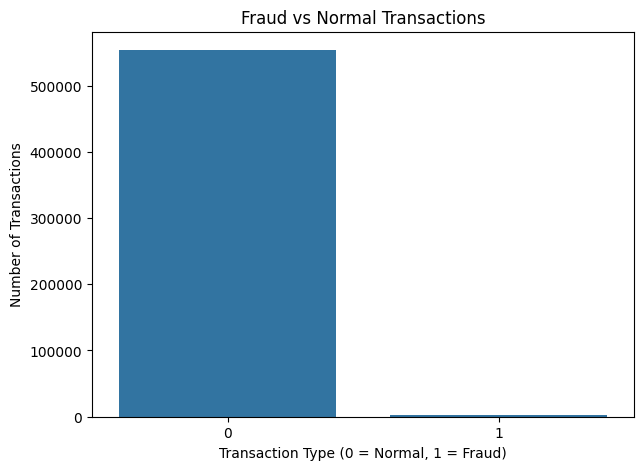

In [15]:

# Visualise class imbalance

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='is_fraud')

plt.title("Fraud vs Normal Transactions")
plt.xlabel("Transaction Type (0 = Normal, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.show()

In [16]:

# STEP 7: Convert date column into datetime

df['trans_date_trans_time'] = pd.to_datetime(
    df['trans_date_trans_time']
)

print("Date conversion successful!")

print(df['trans_date_trans_time'].dtype)


Date conversion successful!
datetime64[ns]


/tmp/ipykernel_727/125381286.py:3: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['trans_date_trans_time'] = pd.to_datetime(


In [17]:

# Find dataset date coverage

start_date = df['trans_date_trans_time'].min()
end_date = df['trans_date_trans_time'].max()

print("First Transaction:", start_date)
print("Last Transaction:", end_date)

print("\nTotal Days Covered:",
      (end_date - start_date).days)

First Transaction: 2020-06-21 12:14:00
Last Transaction: 2020-12-31 23:59:00

Total Days Covered: 193


In [18]:

# Monthly transaction analysis

df['month'] = df['trans_date_trans_time'].dt.to_period('M')

monthly_transactions = df.groupby('month').size()

print(monthly_transactions)

month
2020-06     30058
2020-07     85848
2020-08     88759
2020-09     69533
2020-10     69348
2020-11     72635
2020-12    139538
Freq: M, dtype: int64


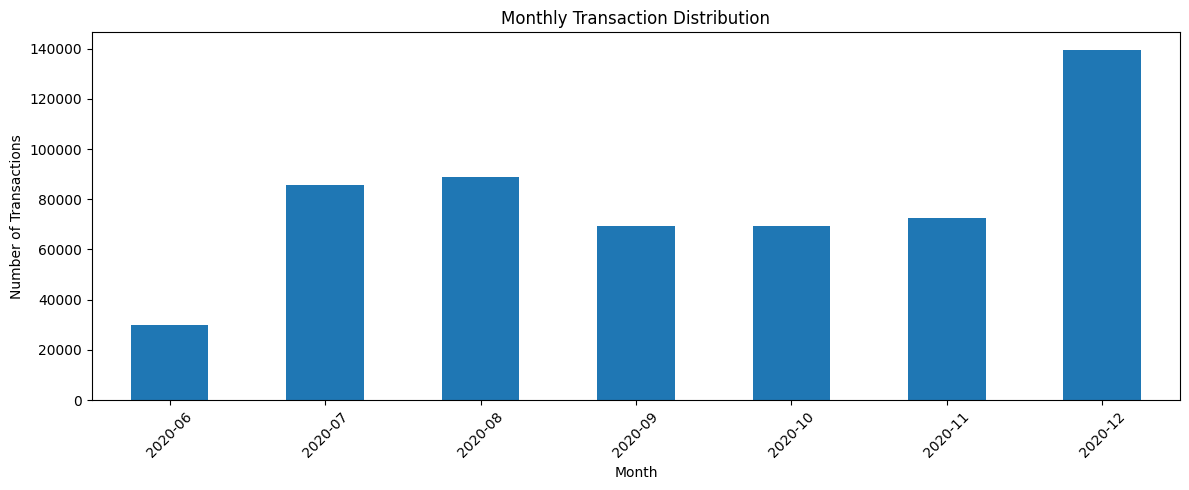

In [19]:

# Monthly transaction graph

plt.figure(figsize=(12, 5))

monthly_transactions.plot(kind='bar')

plt.title("Monthly Transaction Distribution")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [23]:

# STEP 8: Validate important columns

print("Negative Amounts:",
      (df['amt'] < 0).sum())

print("Zero Amounts:",
      (df['amt'] == 0).sum())

print("Missing Transaction IDs:",
      df['trans_num'].isnull().sum())

print("\nFraud Label Categories:")
print(df['is_fraud'].unique())

print("\nNegative or Invalid Amount Check Completed!")

Negative Amounts: 0
Zero Amounts: 0
Missing Transaction IDs: 0

Fraud Label Categories:
[0 1]

Negative or Invalid Amount Check Completed!


In [25]:

# Load testing dataset

test_df = pd.read_csv('/content/Book1.csv')

# Compare dataset sizes

print("Training Dataset:", df.shape)
print("Testing Dataset:", test_df.shape)

# Compare column names

print("\nSame Columns:",
      set(df.columns) == set(test_df.columns))

# Check transaction ID overlap

overlap = set(df['trans_num']).intersection(
    set(test_df['trans_num'])
)

print("Common Transaction IDs:", len(overlap))

Training Dataset: (555719, 24)
Testing Dataset: (555719, 23)

Same Columns: False
Common Transaction IDs: 555719


In [27]:

# Save audited dataset

df.to_csv(
    '/content/audited_Book2.csv',
    index=False
)

print("Audited dataset saved successfully!")

Audited dataset saved successfully!


In [28]:

# Import NumPy
import numpy as np

# Extract transaction amounts
amounts = df['amt'].to_numpy()

# Display first 10 transaction amounts
print("First 10 Transaction Amounts:")
print(amounts[:10])

# Check total transactions
print("\nTotal Transactions:", len(amounts))


First 10 Transaction Amounts:
[  2.86  29.84  41.28  60.05   3.19  19.55 133.93  10.37   4.37  66.54]

Total Transactions: 555719


In [29]:

# Calculate mean transaction amount

mean_amount = np.mean(amounts)

print("Average Transaction Amount:",
      mean_amount)


Average Transaction Amount: 69.3928102332294


In [30]:

# Calculate median

median_amount = np.median(amounts)

print("Median Transaction Amount:",
      median_amount)


Median Transaction Amount: 47.29


In [31]:

# Calculate standard deviation

std_amount = np.std(amounts)

print("Standard Deviation:",
      std_amount)


Standard Deviation: 156.74580032539535


In [32]:

# Calculate transaction quantiles

quantiles = np.quantile(
    amounts,
    [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

print("Transaction Quantiles:")

print(quantiles)


Transaction Quantiles:
[  9.63    47.29    83.01   135.55   193.051  519.8546]


In [33]:

# Minimum and maximum amounts

minimum_amount = np.min(amounts)
maximum_amount = np.max(amounts)

print("Minimum Transaction:", minimum_amount)
print("Maximum Transaction:", maximum_amount)


Minimum Transaction: 1.0
Maximum Transaction: 22768.11


In [34]:

# Calculate IQR

Q1 = np.percentile(amounts, 25)
Q3 = np.percentile(amounts, 75)

IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)


Q1: 9.63
Q3: 83.01
IQR: 73.38000000000001


In [35]:

# Calculate IQR boundaries

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Identify potential outliers

outliers = amounts[
    (amounts < lower_limit) |
    (amounts > upper_limit)
]

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

print("Potential Outliers:", len(outliers))


Lower Limit: -100.44000000000003
Upper Limit: 193.08000000000004
Potential Outliers: 27778


In [36]:

# Calculate Z-scores using NumPy

z_scores = (
    amounts - np.mean(amounts)
) / np.std(amounts)

print("First 10 Z-scores:")
print(z_scores[:10])


First 10 Z-scores:
[-0.42446311 -0.25233729 -0.17935288 -0.05960485 -0.42235779 -0.31798498
  0.41173154 -0.37655114 -0.41482968 -0.01820023]


In [37]:

# Calculate median

median = np.median(amounts)

# Calculate Median Absolute Deviation

MAD = np.median(
    np.abs(amounts - median)
)

# Calculate robust Z-scores

if MAD != 0:

    robust_z = (
        0.6745 * (amounts - median)
    ) / MAD

else:

    robust_z = np.zeros_like(amounts)

print("Median:", median)
print("MAD:", MAD)

print("\nFirst 10 Robust Z-scores:")
print(robust_z[:10])


Median: 47.29
MAD: 37.34

First 10 Robust Z-scores:
[-0.80257191 -0.31521224 -0.10856307  0.2304933  -0.79661087 -0.50108811
  1.56504231 -0.66691323 -0.77529566  0.34772697]


In [38]:

# Identify transactions with high robust Z-scores

suspicious_mask = np.abs(robust_z) > 3.5

suspicious_amounts = amounts[suspicious_mask]

print("Potentially Unusual Transactions:",
      len(suspicious_amounts))

print("\nFirst 10 Unusual Amounts:")
print(suspicious_amounts[:10])


Potentially Unusual Transactions: 16413

First 10 Unusual Amounts:
[ 242.35  558.03 1199.45  456.22 1881.53  552.46  252.46  355.74  313.38
  246.73]


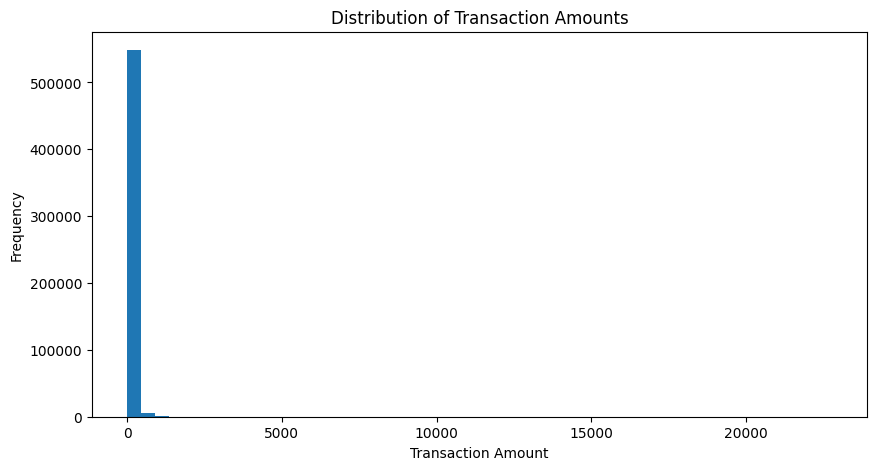

In [39]:

# Transaction amount distribution

plt.figure(figsize=(10, 5))

plt.hist(amounts, bins=50)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()


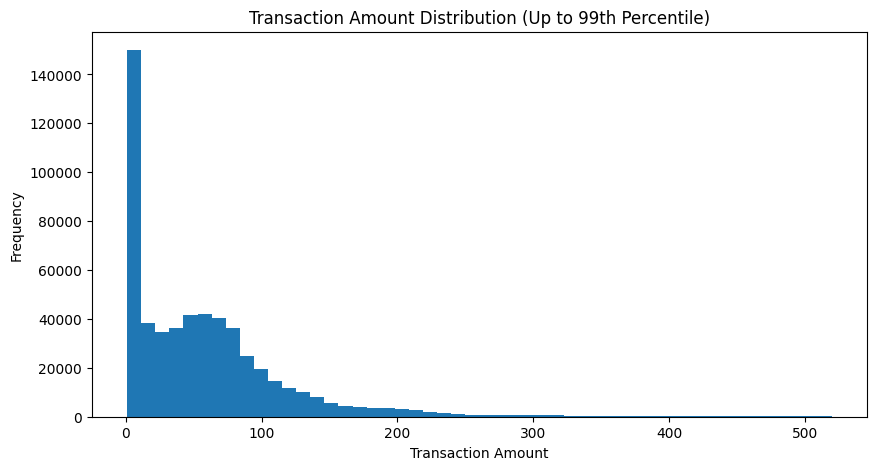

In [40]:

# Focus on transaction amounts below the 99th percentile

limit = np.percentile(amounts, 99)

plt.figure(figsize=(10, 5))

plt.hist(
    amounts[amounts <= limit],
    bins=50
)

plt.title("Transaction Amount Distribution (Up to 99th Percentile)")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()


In [41]:

# Check required columns

required_columns = [
    'trans_date_trans_time',
    'cc_num',
    'merchant',
    'category',
    'amt',
    'is_fraud'
]

print("Required columns available:")

for column in required_columns:
    print(column, column in df.columns)


Required columns available:
trans_date_trans_time True
cc_num True
merchant True
category True
amt True
is_fraud True


In [42]:

# Convert transaction time into datetime

df['trans_date_trans_time'] = pd.to_datetime(
    df['trans_date_trans_time']
)

# Sort transactions by time

df = df.sort_values(
    'trans_date_trans_time'
).reset_index(drop=True)

print("Dataset sorted by transaction time!")


Dataset sorted by transaction time!


In [43]:

# Extract transaction hour

df['transaction_hour'] = (
    df['trans_date_trans_time'].dt.hour
)

print(df[['trans_date_trans_time',
          'transaction_hour']].head())


  trans_date_trans_time  transaction_hour
0   2020-06-21 12:14:00                12
1   2020-06-21 12:14:00                12
2   2020-06-21 12:14:00                12
3   2020-06-21 12:15:00                12
4   2020-06-21 12:15:00                12


In [44]:

# Create night transaction feature

df['is_night'] = (
    (df['transaction_hour'] >= 0) &
    (df['transaction_hour'] < 6)
).astype(int)

print(df[['transaction_hour',
          'is_night']].head(10))


   transaction_hour  is_night
0                12         0
1                12         0
2                12         0
3                12         0
4                12         0
5                12         0
6                12         0
7                12         0
8                12         0
9                12         0


In [45]:

# Count transactions made by each customer

df['customer_transaction_count'] = (
    df.groupby('cc_num')['trans_num']
      .transform('count')
)

print(df[['cc_num',
          'customer_transaction_count']].head(10))


         cc_num  customer_transaction_count
0  2.290000e+15                        2647
1  3.570000e+15                        9028
2  3.600000e+15                        7869
3  3.590000e+15                       10141
4  3.530000e+15                       11914
5  3.040000e+13                        6110
6  2.130000e+14                       22329
7  3.590000e+15                       10141
8  3.600000e+15                        7869
9  3.550000e+15                        8906


In [46]:

# Calculate customer average transaction amount

df['customer_avg_amount'] = (
    df.groupby('cc_num')['amt']
      .transform('mean')
)

print(df[['cc_num',
          'amt',
          'customer_avg_amount']].head(10))


         cc_num     amt  customer_avg_amount
0  2.290000e+15    2.86            67.810952
1  3.570000e+15   29.84            70.989235
2  3.600000e+15   41.28            69.812402
3  3.590000e+15   60.05            74.940389
4  3.530000e+15    3.19            67.673746
5  3.040000e+13   19.55            67.760101
6  2.130000e+14  133.93            69.856593
7  3.590000e+15   10.37            74.940389
8  3.600000e+15    4.37            69.812402
9  3.550000e+15   66.54            65.990847


In [47]:

# Calculate maximum transaction amount per customer

df['customer_max_amount'] = (
    df.groupby('cc_num')['amt']
      .transform('max')
)

print(df[['cc_num',
          'amt',
          'customer_max_amount']].head(10))


         cc_num     amt  customer_max_amount
0  2.290000e+15    2.86              3679.74
1  3.570000e+15   29.84             16837.08
2  3.600000e+15   41.28             12882.33
3  3.590000e+15   60.05              3778.46
4  3.530000e+15    3.19              6782.92
5  3.040000e+13   19.55              3396.84
6  2.130000e+14  133.93             11586.34
7  3.590000e+15   10.37              3778.46
8  3.600000e+15    4.37             12882.33
9  3.550000e+15   66.54              5421.72


In [48]:

# Calculate total customer spending

df['customer_total_spending'] = (
    df.groupby('cc_num')['amt']
      .transform('sum')
)

print(df[['cc_num',
          'amt',
          'customer_total_spending']].head(10))


         cc_num     amt  customer_total_spending
0  2.290000e+15    2.86                179495.59
1  3.570000e+15   29.84                640890.81
2  3.600000e+15   41.28                549353.79
3  3.590000e+15   60.05                759970.48
4  3.530000e+15    3.19                806265.01
5  3.040000e+13   19.55                414014.22
6  2.130000e+14  133.93               1559827.87
7  3.590000e+15   10.37                759970.48
8  3.600000e+15    4.37                549353.79
9  3.550000e+15   66.54                587714.48


In [54]:
# Sort the dataframe chronologically to ensure rolling window calculation is accurate
df = df.sort_values('trans_date_trans_time').reset_index(drop=True)

# Calculate customer transaction velocity cleanly by using a datetime index temporary calculation
temp_df = df.set_index('trans_date_trans_time')

# Group by credit card number and apply a rolling 60-minute window
# 'closed="left"' ensures we only count prior transactions (excluding the current one)
rolling_count = (
    temp_df.groupby('cc_num')['amt']
    .rolling('60min', closed='left')
    .count()
    .reset_index(level=0, drop=True) # Drop the 'cc_num' grouping level to align with datetime index
)

# Map the computed rolling counts back to the sorted dataframe
# Since both df and rolling_count are chronologically aligned and have matching index timestamps, we can join them
df['transactions_last_60min'] = rolling_count.values
df['transactions_last_60min'] = df['transactions_last_60min'].fillna(0).astype(int)

# Verify the results
print(df[['cc_num', 'trans_date_trans_time', 'transactions_last_60min']].head(10))

         cc_num trans_date_trans_time  transactions_last_60min
0  2.290000e+15   2020-06-21 12:14:00                        0
1  3.570000e+15   2020-06-21 12:14:00                        0
2  3.600000e+15   2020-06-21 12:14:00                        0
3  3.590000e+15   2020-06-21 12:15:00                        0
4  3.530000e+15   2020-06-21 12:15:00                        0
5  3.040000e+13   2020-06-21 12:15:00                        0
6  2.130000e+14   2020-06-21 12:15:00                        0
7  3.590000e+15   2020-06-21 12:15:00                        0
8  3.600000e+15   2020-06-21 12:16:00                        0
9  3.550000e+15   2020-06-21 12:16:00                        0


In [60]:
# Sort the dataframe chronologically to ensure rolling window calculation is accurate
df = df.sort_values('trans_date_trans_time').reset_index(drop=True)

# Create a temporary index with datetime for the rolling calculation
temp_df = df.set_index('trans_date_trans_time')

# Calculate customer spending during previous 60 minutes
# 'closed="left"' ensures we only sum prior transaction amounts (excluding the current one)
rolling_spending = (
    temp_df.groupby('cc_num')['amt']
    .rolling('60min', closed='left')
    .sum()
    .reset_index(level=0, drop=True) # Drop the 'cc_num' grouping level to align with datetime index
)

# Map the computed rolling sums back to the sorted dataframe safely using .values
df['spending_last_60min'] = rolling_spending.values
df['spending_last_60min'] = df['spending_last_60min'].fillna(0.0)

# Verify the results
print(df[['cc_num', 'amt', 'spending_last_60min']].head(10))

         cc_num     amt  spending_last_60min
0  2.290000e+15    2.86                  0.0
1  3.570000e+15   29.84                  0.0
2  3.600000e+15   41.28                  0.0
3  3.590000e+15   60.05                  0.0
4  3.530000e+15    3.19                  0.0
5  3.040000e+13   19.55                  0.0
6  2.130000e+14  133.93                  0.0
7  3.590000e+15   10.37                  0.0
8  3.600000e+15    4.37                  0.0
9  3.550000e+15   66.54                  0.0


In [61]:

# Count transactions for each merchant

df['merchant_transaction_count'] = (
    df.groupby('merchant')['trans_num']
      .transform('count')
)

print(df[['merchant',
          'merchant_transaction_count']].head(10))


                               merchant  merchant_transaction_count
0                 fraud_Kirlin and Sons                         736
1                  fraud_Sporer-Keebler                         785
2  fraud_Swaniawski, Nitzsche and Welch                         755
3                     fraud_Haley Group                         711
4                 fraud_Johnston-Casper                         370
5                   fraud_Daugherty LLC                         971
6                   fraud_Romaguera Ltd                         717
7                     fraud_Reichel LLC                         787
8     fraud_Goyette, Howell and Collier                         952
9                   fraud_Kilback Group                         766


In [62]:

# Calculate average spending by category

df['category_avg_amount'] = (
    df.groupby('category')['amt']
      .transform('mean')
)

print(df[['category',
          'amt',
          'category_avg_amount']].head(10))


         category     amt  category_avg_amount
0   personal_care    2.86            48.233021
1   personal_care   29.84            48.233021
2  health_fitness   41.28            53.867432
3        misc_pos   60.05            62.182246
4          travel    3.19           112.389683
5       kids_pets   19.55            57.506913
6  health_fitness  133.93            53.867432
7   personal_care   10.37            48.233021
8    shopping_pos    4.37            76.862457
9     food_dining   66.54            50.777938


In [63]:

# Compare transaction amount with customer average

df['customer_spending_ratio'] = (
    df['amt'] /
    df['customer_avg_amount'].replace(0, np.nan)
)

print(df[['cc_num',
          'amt',
          'customer_avg_amount',
          'customer_spending_ratio']].head(10))


         cc_num     amt  customer_avg_amount  customer_spending_ratio
0  2.290000e+15    2.86            67.810952                 0.042176
1  3.570000e+15   29.84            70.989235                 0.420345
2  3.600000e+15   41.28            69.812402                 0.591299
3  3.590000e+15   60.05            74.940389                 0.801304
4  3.530000e+15    3.19            67.673746                 0.047138
5  3.040000e+13   19.55            67.760101                 0.288518
6  2.130000e+14  133.93            69.856593                 1.917213
7  3.590000e+15   10.37            74.940389                 0.138377
8  3.600000e+15    4.37            69.812402                 0.062596
9  3.550000e+15   66.54            65.990847                 1.008322


In [64]:

# Display engineered features

new_features = [
    'transaction_hour',
    'is_night',
    'customer_transaction_count',
    'customer_avg_amount',
    'customer_max_amount',
    'customer_total_spending',
    'transactions_last_60min',
    'spending_last_60min',
    'merchant_transaction_count',
    'category_avg_amount',
    'customer_spending_ratio'
]

df[new_features].head(10)


,transaction_hour,is_night,customer_transaction_count,customer_avg_amount,customer_max_amount,customer_total_spending,transactions_last_60min,spending_last_60min,merchant_transaction_count,category_avg_amount,customer_spending_ratio
0,12,0,2647,67.810952,3679.74,179495.59,0,0.0,736,48.233021,0.042176
1,12,0,9028,70.989235,16837.08,640890.81,0,0.0,785,48.233021,0.420345
2,12,0,7869,69.812402,12882.33,549353.79,0,0.0,755,53.867432,0.591299
3,12,0,10141,74.940389,3778.46,759970.48,0,0.0,711,62.182246,0.801304
4,12,0,11914,67.673746,6782.92,806265.01,0,0.0,370,112.389683,0.047138
5,12,0,6110,67.760101,3396.84,414014.22,0,0.0,971,57.506913,0.288518
6,12,0,22329,69.856593,11586.34,1559827.87,0,0.0,717,53.867432,1.917213
7,12,0,10141,74.940389,3778.46,759970.48,0,0.0,787,48.233021,0.138377
8,12,0,7869,69.812402,12882.33,549353.79,0,0.0,952,76.862457,0.062596
9,12,0,8906,65.990847,5421.72,587714.48,0,0.0,766,50.777938,1.008322


In [65]:

# Customer-level summary

customer_summary = (
    df.groupby('cc_num')
      .agg(
          total_transactions=('trans_num', 'count'),
          total_spending=('amt', 'sum'),
          average_spending=('amt', 'mean'),
          maximum_spending=('amt', 'max'),
          fraud_transactions=('is_fraud', 'sum')
      )
      .reset_index()
)

print(customer_summary.head(10))


         cc_num  total_transactions  total_spending  average_spending  \
0  6.041621e+10                 678        45086.65         66.499484   
1  6.042293e+10                 669        38422.75         57.433109   
2  6.042310e+10                 228        12451.92         54.613684   
3  6.042785e+10                 215        20733.64         96.435535   
4  6.048700e+10                 239        21951.13         91.845732   
5  6.049060e+10                 455        28978.73         63.689516   
6  6.049559e+10                 224        18625.93         83.151473   
7  5.020000e+11                4176       281524.65         67.414907   
8  5.040000e+11                1753       104889.07         59.834039   
9  5.610000e+11                 226        12716.34         56.266991   

   maximum_spending  fraud_transactions  
0           3437.46                   0  
1            572.44                   0  
2            497.97                   0  
3            592.90         

In [66]:

# Customer-level summary

customer_summary = (
    df.groupby('cc_num')
      .agg(
          total_transactions=('trans_num', 'count'),
          total_spending=('amt', 'sum'),
          average_spending=('amt', 'mean'),
          maximum_spending=('amt', 'max'),
          fraud_transactions=('is_fraud', 'sum')
      )
      .reset_index()
)

print(customer_summary.head(10))


         cc_num  total_transactions  total_spending  average_spending  \
0  6.041621e+10                 678        45086.65         66.499484   
1  6.042293e+10                 669        38422.75         57.433109   
2  6.042310e+10                 228        12451.92         54.613684   
3  6.042785e+10                 215        20733.64         96.435535   
4  6.048700e+10                 239        21951.13         91.845732   
5  6.049060e+10                 455        28978.73         63.689516   
6  6.049559e+10                 224        18625.93         83.151473   
7  5.020000e+11                4176       281524.65         67.414907   
8  5.040000e+11                1753       104889.07         59.834039   
9  5.610000e+11                 226        12716.34         56.266991   

   maximum_spending  fraud_transactions  
0           3437.46                   0  
1            572.44                   0  
2            497.97                   0  
3            592.90         

In [67]:

# Save the engineered dataset

df.to_csv(
    '/content/fraud_feature_engineered.csv',
    index=False
)

customer_summary.to_csv(
    '/content/customer_summary.csv',
    index=False
)

print("Feature engineering completed!")
print("Files saved successfully!")


Feature engineering completed!
Files saved successfully!


In [68]:

# Separate normal and fraudulent transactions

normal = df[df['is_fraud'] == 0]

fraud = df[df['is_fraud'] == 1]

print("Normal Transactions:", len(normal))
print("Fraudulent Transactions:", len(fraud))

print("Total Transactions:", len(df))


Normal Transactions: 553574
Fraudulent Transactions: 2145
Total Transactions: 555719


In [69]:

# Compare average transaction amounts

normal_avg = normal['amt'].mean()

fraud_avg = fraud['amt'].mean()

print("Normal Average Amount:", normal_avg)

print("Fraud Average Amount:", fraud_avg)


Normal Average Amount: 67.61440824532944
Fraud Average Amount: 528.3564941724942


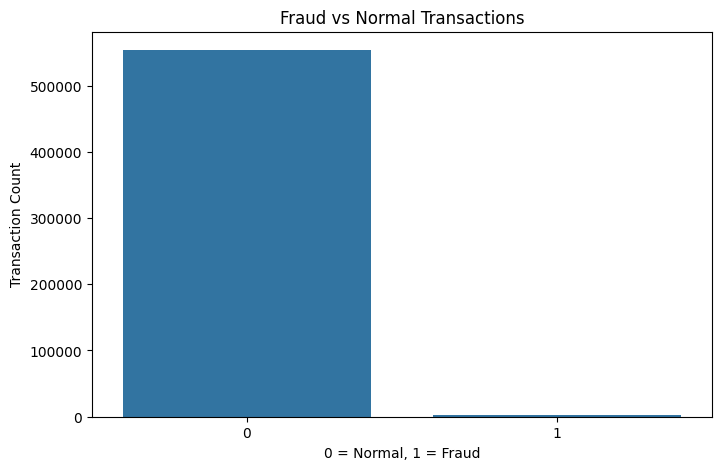

In [70]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='is_fraud'
)

plt.title("Fraud vs Normal Transactions")
plt.xlabel("0 = Normal, 1 = Fraud")
plt.ylabel("Transaction Count")

plt.show()


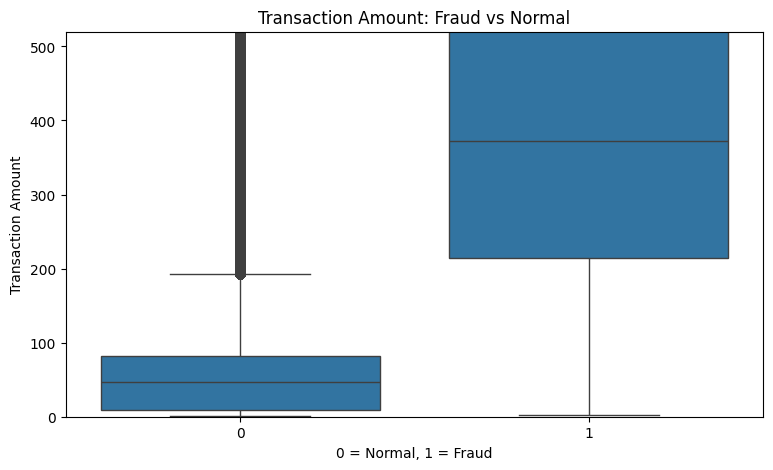

In [71]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='is_fraud',
    y='amt'
)

plt.ylim(0, df['amt'].quantile(0.99))

plt.title("Transaction Amount: Fraud vs Normal")
plt.xlabel("0 = Normal, 1 = Fraud")
plt.ylabel("Transaction Amount")

plt.show()


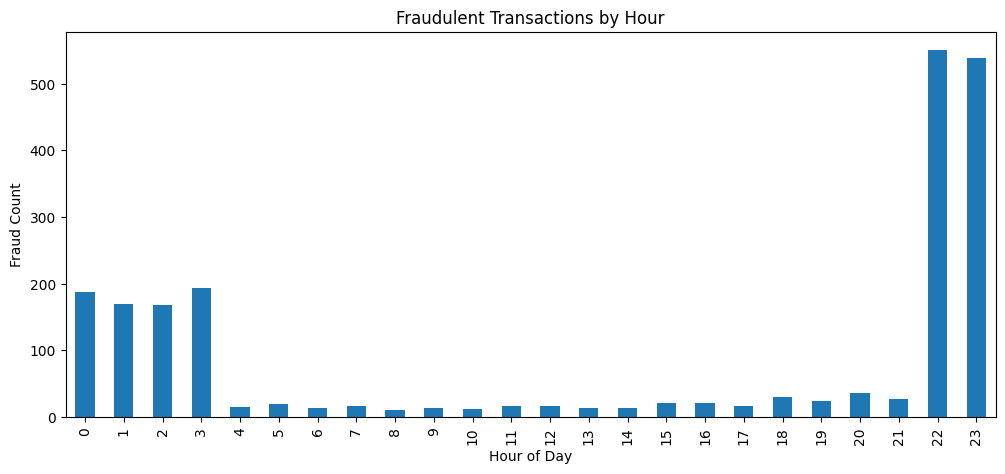

In [72]:

# Count fraud transactions by hour

fraud_by_hour = (
    fraud.groupby('transaction_hour')
         .size()
)

plt.figure(figsize=(12, 5))

fraud_by_hour.plot(kind='bar')

plt.title("Fraudulent Transactions by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Fraud Count")

plt.show()


In [73]:

# Calculate fraud rate by category

category_analysis = (
    df.groupby('category')
      .agg(
          total_transactions=('is_fraud', 'count'),
          fraud_transactions=('is_fraud', 'sum')
      )
)

category_analysis['fraud_rate'] = (
    category_analysis['fraud_transactions'] /
    category_analysis['total_transactions']
) * 100

category_analysis = category_analysis.sort_values(
    'fraud_rate',
    ascending=False
)

print(category_analysis)


                total_transactions  fraud_transactions  fraud_rate
category                                                          
shopping_net                 41779                 506    1.211135
misc_net                     27367                 267    0.975628
grocery_pos                  52553                 485    0.922878
shopping_pos                 49791                 213    0.427788
gas_transport                56370                 154    0.273195
travel                       17449                  40    0.229239
grocery_net                  19426                  41    0.211057
misc_pos                     34574                  72    0.208249
personal_care                39327                  70    0.177995
entertainment                40104                  59    0.147117
health_fitness               36674                  52    0.141790
food_dining                  39268                  54    0.137517
kids_pets                    48692                  65    0.13

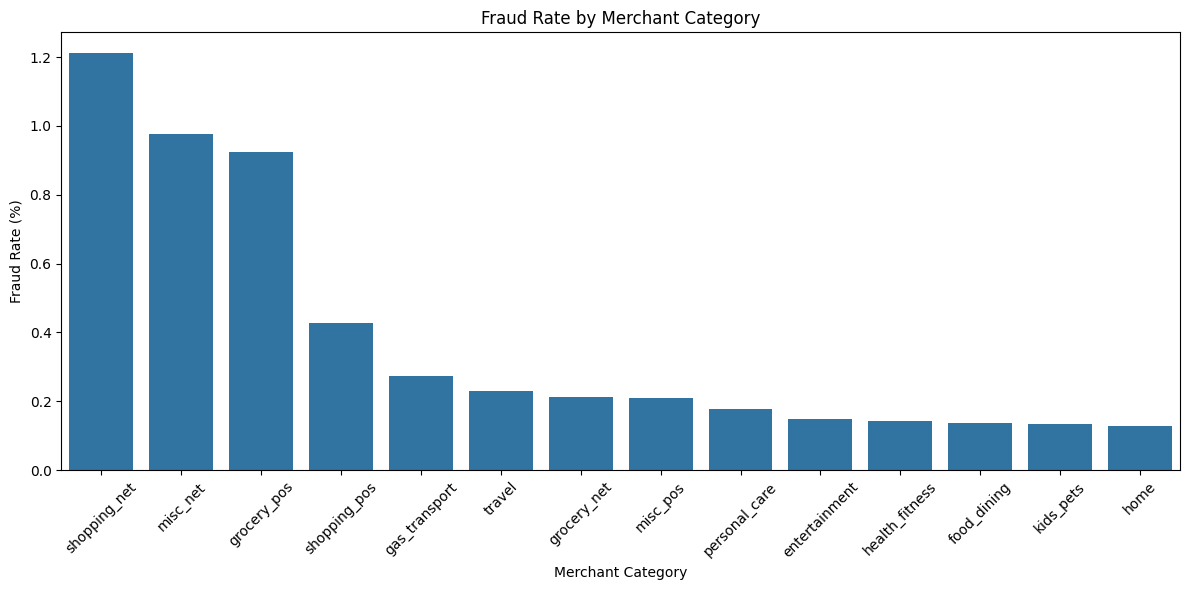

In [74]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_analysis.reset_index(),
    x='category',
    y='fraud_rate'
)

plt.title("Fraud Rate by Merchant Category")
plt.xlabel("Merchant Category")
plt.ylabel("Fraud Rate (%)")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


In [75]:

# Find customers with most fraud transactions

customer_fraud = (
    df.groupby('cc_num')['is_fraud']
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

print(customer_fraud)


cc_num
3.590000e+15    90
1.800000e+14    76
2.130000e+14    68
3.580000e+15    65
6.760000e+11    60
3.020000e+13    55
3.530000e+15    51
3.760000e+14    50
6.010000e+15    50
3.050000e+13    49
Name: is_fraud, dtype: int64


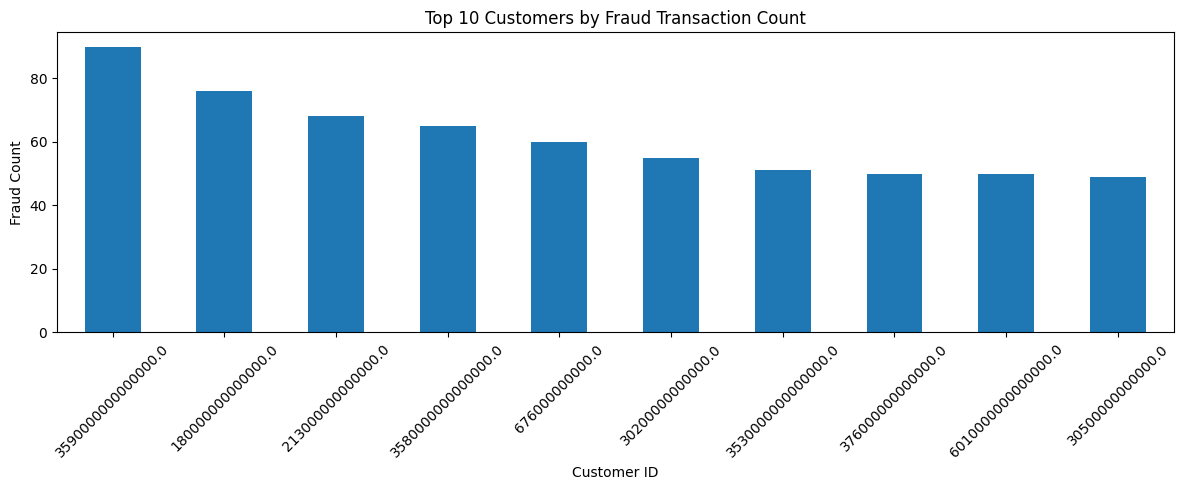

In [76]:

plt.figure(figsize=(12, 5))

customer_fraud.plot(kind='bar')

plt.title("Top 10 Customers by Fraud Transaction Count")
plt.xlabel("Customer ID")
plt.ylabel("Fraud Count")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


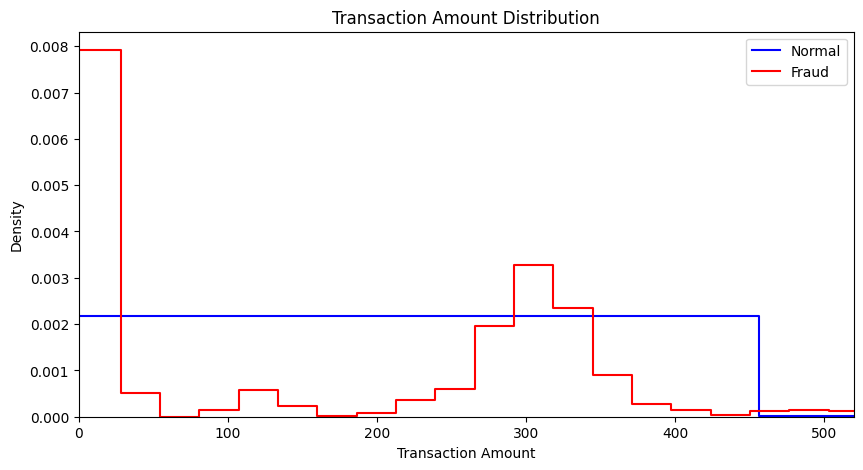

In [77]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=normal,
    x='amt',
    bins=50,
    color='blue',
    label='Normal',
    stat='density',
    element='step',
    fill=False
)

sns.histplot(
    data=fraud,
    x='amt',
    bins=50,
    color='red',
    label='Fraud',
    stat='density',
    element='step',
    fill=False
)

plt.xlim(0, df['amt'].quantile(0.99))

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Density")

plt.legend()
plt.show()


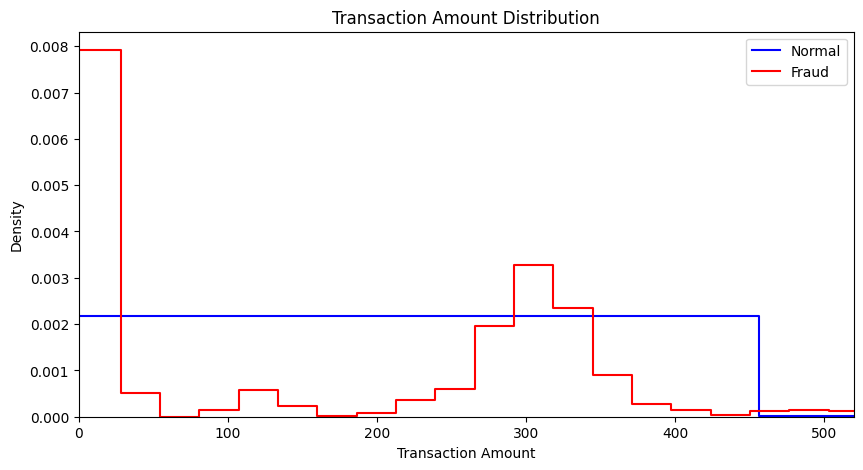

In [78]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=normal,
    x='amt',
    bins=50,
    color='blue',
    label='Normal',
    stat='density',
    element='step',
    fill=False
)

sns.histplot(
    data=fraud,
    x='amt',
    bins=50,
    color='red',
    label='Fraud',
    stat='density',
    element='step',
    fill=False
)

plt.xlim(0, df['amt'].quantile(0.99))

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Density")

plt.legend()
plt.show()


In [79]:

# Fraud rate by hour

hourly_analysis = (
    df.groupby('transaction_hour')
      .agg(
          total_transactions=('is_fraud', 'count'),
          fraud_transactions=('is_fraud', 'sum')
      )
)

hourly_analysis['fraud_rate'] = (
    hourly_analysis['fraud_transactions'] /
    hourly_analysis['total_transactions']
) * 100

print(hourly_analysis)


                  total_transactions  fraud_transactions  fraud_rate
transaction_hour                                                    
0                              18153                 188    1.035641
1                              18461                 169    0.915443
2                              18140                 168    0.926130
3                              18199                 194    1.065993
4                              18075                  15    0.082988
5                              17917                  20    0.111626
6                              18106                  14    0.077322
7                              18098                  16    0.088408
8                              17993                  10    0.055577
9                              18046                  14    0.077580
10                             18049                  12    0.066486
11                             18088                  17    0.093985
12                             280

In [80]:

# Generate project findings

print("FRAUD ANALYSIS REPORT")
print("-" * 40)

print("Total Transactions:", len(df))

print("Fraud Transactions:", len(fraud))

print("Normal Transactions:", len(normal))

print("Overall Fraud Rate:",
      round(df['is_fraud'].mean() * 100, 4), "%")

print("Average Normal Amount:",
      round(normal['amt'].mean(), 2))

print("Average Fraud Amount:",
      round(fraud['amt'].mean(), 2))

print("Highest Fraud Category:",
      category_analysis.index[0])

print("Highest Fraud Hour:",
      hourly_analysis['fraud_rate'].idxmax())


FRAUD ANALYSIS REPORT
----------------------------------------
Total Transactions: 555719
Fraud Transactions: 2145
Normal Transactions: 553574
Overall Fraud Rate: 0.386 %
Average Normal Amount: 67.61
Average Fraud Amount: 528.36
Highest Fraud Category: shopping_net
Highest Fraud Hour: 22


In [81]:

# Save category and hourly analysis

category_analysis.to_csv(
    '/content/category_fraud_analysis.csv'
)

hourly_analysis.to_csv(
    '/content/hourly_fraud_analysis.csv'
)

customer_fraud.to_csv(
    '/content/customer_fraud_analysis.csv'
)

print("Analysis results saved successfully!")


Analysis results saved successfully!


In [82]:

# STEP 1: Prepare the dataset

df = df.sort_values(
    'trans_date_trans_time'
).reset_index(drop=True)

print("Dataset prepared successfully!")
print(df.shape)


Dataset prepared successfully!
(555719, 37)


In [83]:

# STEP 2: Calculate robust Z-score

amounts = df['amt'].to_numpy()

median_amount = np.median(amounts)

MAD = np.median(
    np.abs(amounts - median_amount)
)

if MAD != 0:
    df['amount_robust_z'] = (
        0.6745 * (amounts - median_amount) / MAD
    )
else:
    df['amount_robust_z'] = 0

# Flag unusual amounts

df['high_amount_flag'] = (
    np.abs(df['amount_robust_z']) > 3.5
).astype(int)

print("Unusual Amount Transactions:",
      df['high_amount_flag'].sum())


Unusual Amount Transactions: 16413


In [84]:

# STEP 3: High transaction velocity

df['high_velocity_flag'] = (
    df['transactions_last_60min'] >= 5
).astype(int)

print("High Velocity Transactions:",
      df['high_velocity_flag'].sum())


High Velocity Transactions: 62388


In [85]:

# STEP 4: Calculate historical customer median

df['past_customer_median'] = (
    df.groupby('cc_num')['amt']
      .transform(
          lambda s: s.shift().expanding(
              min_periods=5
          ).median()
      )
)

# Calculate spending ratio

df['past_spending_ratio'] = (
    df['amt'] /
    df['past_customer_median'].replace(0, np.nan)
)

# Flag transactions 3 times higher than past median

df['customer_spending_flag'] = (
    df['past_spending_ratio'] > 3
).fillna(False).astype(int)

print("Unusual Customer Spending:",
      df['customer_spending_flag'].sum())


Unusual Customer Spending: 57549


In [86]:

# STEP 5: Night transaction flag

df['night_transaction_flag'] = (
    df['transaction_hour'].between(0, 5)
).astype(int)

print("Night Transactions:",
      df['night_transaction_flag'].sum())


Night Transactions: 108945


In [87]:

# STEP 6: Calculate combined anomaly score

df['anomaly_score'] = (
    df['high_amount_flag'] +
    df['high_velocity_flag'] +
    df['customer_spending_flag']
)

print("Anomaly Score Distribution:")

print(df['anomaly_score'].value_counts().sort_index())


Anomaly Score Distribution:
anomaly_score
0    442083
1     92825
2     18908
3      1903
Name: count, dtype: int64


In [88]:

# STEP 7: Assign risk categories

df['risk_category'] = np.select(
    [
        df['anomaly_score'] == 0,
        df['anomaly_score'] == 1,
        df['anomaly_score'] == 2,
        df['anomaly_score'] == 3
    ],
    [
        'Low Risk',
        'Moderate Risk',
        'High Risk',
        'Very High Risk'
    ],
    default='Unknown'
)

print(df['risk_category'].value_counts())


risk_category
Low Risk          442083
Moderate Risk      92825
High Risk          18908
Very High Risk      1903
Name: count, dtype: int64


In [89]:

# STEP 8: Display suspicious transactions

suspicious_transactions = df[
    df['anomaly_score'] >= 1
]

columns_to_display = [
    'trans_date_trans_time',
    'cc_num',
    'merchant',
    'amt',
    'anomaly_score',
    'risk_category'
]

print("Suspicious Transactions:")

display(
    suspicious_transactions[
        columns_to_display
    ].head(20)
)


Suspicious Transactions:


,trans_date_trans_time,cc_num,merchant,amt,anomaly_score,risk_category
100,2020-06-21 12:45:00,6.590000e+15,fraud_Greenholt Ltd,242.35,1,Moderate Risk
130,2020-06-21 12:55:00,4.680000e+12,fraud_Gislason Group,558.03,1,Moderate Risk
161,2020-06-21 13:07:00,6.010000e+15,fraud_Medhurst PLC,118.21,1,Moderate Risk
165,2020-06-21 13:08:00,3.580000e+15,fraud_Waelchi Inc,64.36,1,Moderate Risk
167,2020-06-21 13:08:00,6.010000e+15,fraud_Schumm PLC,1199.45,2,High Risk
209,2020-06-21 13:24:00,2.130000e+14,"fraud_Romaguera, Wehner and Tromp",79.56,1,Moderate Risk
214,2020-06-21 13:26:00,3.520000e+15,fraud_Gleason and Sons,64.96,1,Moderate Risk
235,2020-06-21 13:33:00,2.130000e+14,fraud_Crona and Sons,169.09,1,Moderate Risk
250,2020-06-21 13:40:00,6.760000e+11,fraud_Erdman-Ebert,51.44,1,Moderate Risk
276,2020-06-21 13:48:00,6.760000e+11,"fraud_Schaefer, Fay and Hilll",102.43,1,Moderate Risk


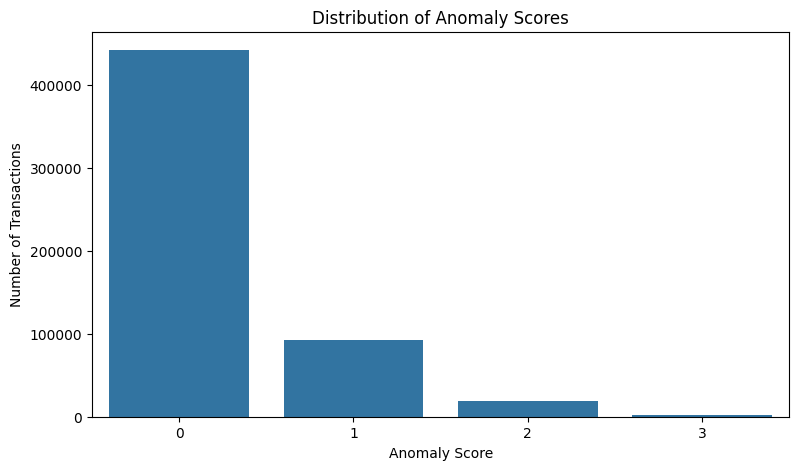

In [90]:

# STEP 9: Visualize anomaly scores

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='anomaly_score'
)

plt.title("Distribution of Anomaly Scores")
plt.xlabel("Anomaly Score")
plt.ylabel("Number of Transactions")

plt.show()


In [91]:

# STEP 10: Save screening results

df.to_csv(
    '/content/fraud_anomaly_screening.csv',
    index=False
)

suspicious_transactions.to_csv(
    '/content/suspicious_transactions.csv',
    index=False
)

print("Anomaly screening completed!")
print("Results saved successfully!")


Anomaly screening completed!
Results saved successfully!


In [92]:
# Sort transactions by date
df = df.sort_values('trans_date_trans_time').reset_index(drop=True)

# Split data chronologically
split_index = int(len(df) * 0.80)

train_eval = df.iloc[:split_index].copy()
valid_eval = df.iloc[split_index:].copy()

print("Training transactions:", len(train_eval))
print("Validation transactions:", len(valid_eval))

print("Training date range:")
print(train_eval['trans_date_trans_time'].min())
print(train_eval['trans_date_trans_time'].max())

print("Validation date range:")
print(valid_eval['trans_date_trans_time'].min())
print(valid_eval['trans_date_trans_time'].max())

Training transactions: 444575
Validation transactions: 111144
Training date range:
2020-06-21 12:14:00
2020-12-07 13:35:00
Validation date range:
2020-12-07 13:35:00
2020-12-31 23:59:00


In [93]:
# Get training transaction amounts
train_amounts = train_eval['amt'].to_numpy()

# Calculate median and MAD
train_median = np.median(train_amounts)

train_mad = np.median(
    np.abs(train_amounts - train_median)
)

print("Training median:", train_median)
print("Training MAD:", train_mad)

Training median: 47.4
Training MAD: 37.43


In [94]:
if train_mad > 0:

    valid_eval['amount_robust_z'] = (
        0.6745 *
        (valid_eval['amt'] - train_median) /
        train_mad
    )

else:

    valid_eval['amount_robust_z'] = 0

# Flag unusual transaction amounts
valid_eval['high_amount_flag'] = (
    np.abs(valid_eval['amount_robust_z']) > 3.5
).astype(int)

In [95]:
# High transaction velocity
valid_eval['high_velocity_flag'] = (
    valid_eval['transactions_last_60min'] >= 5
).astype(int)

# Unusual spending compared with past customer behaviour
valid_eval['customer_spending_flag'] = (
    valid_eval['past_spending_ratio'] > 3
).fillna(False).astype(int)

# Combine anomaly rules
valid_eval['anomaly_score'] = (
    valid_eval['high_amount_flag'] +
    valid_eval['high_velocity_flag'] +
    valid_eval['customer_spending_flag']
)

print(valid_eval['anomaly_score'].value_counts().sort_index())

anomaly_score
0    83323
1    23380
2     3856
3      585
Name: count, dtype: int64


In [96]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score, recall_score, f1_score

y_true = valid_eval['is_fraud']

results = []

# Try three different thresholds
for threshold in [1, 2, 3]:

    y_pred = (
        valid_eval['anomaly_score'] >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_true, y_pred, zero_division=0
    )

    recall = recall_score(
        y_true, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_true, y_pred, zero_division=0
    )

    false_positive_rate = fp / (fp + tn) if (fp + tn) else 0

    review_rate = y_pred.mean() * 100

    results.append({
        'Threshold': threshold,
        'TP': tp,
        'FP': fp,
        'TN': tn,
        'FN': fn,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'False Positive Rate': false_positive_rate,
        'Review Rate (%)': review_rate
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

   Threshold   TP     FP      TN   FN  Precision  Recall  F1 Score  \
0          1  161  27660   83300   23     0.0058  0.8750    0.0115   
1          2  137   4304  106656   47     0.0308  0.7446    0.0592   
2          3   36    549  110411  148     0.0615  0.1957    0.0936   

   False Positive Rate  Review Rate (%)  
0               0.2493          25.0315  
1               0.0388           3.9957  
2               0.0049           0.5263  


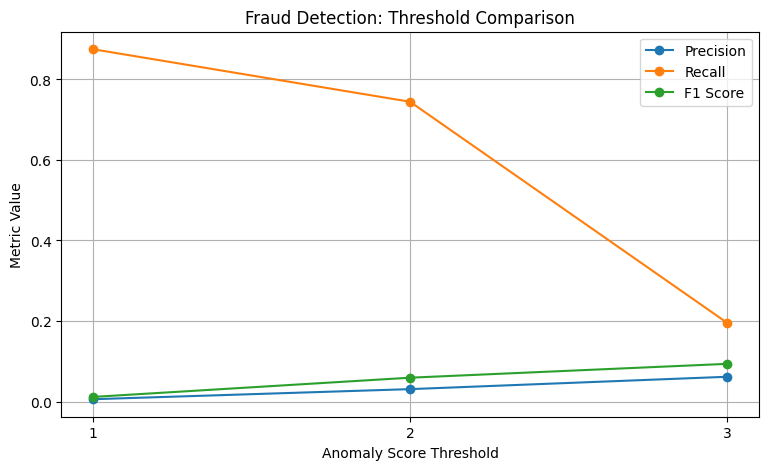

In [97]:
plt.figure(figsize=(9, 5))

plt.plot(
    results_df['Threshold'],
    results_df['Precision'],
    marker='o',
    label='Precision'
)

plt.plot(
    results_df['Threshold'],
    results_df['Recall'],
    marker='o',
    label='Recall'
)

plt.plot(
    results_df['Threshold'],
    results_df['F1 Score'],
    marker='o',
    label='F1 Score'
)

plt.xlabel('Anomaly Score Threshold')
plt.ylabel('Metric Value')
plt.title('Fraud Detection: Threshold Comparison')

plt.xticks([1, 2, 3])
plt.legend()
plt.grid(True)

plt.show()

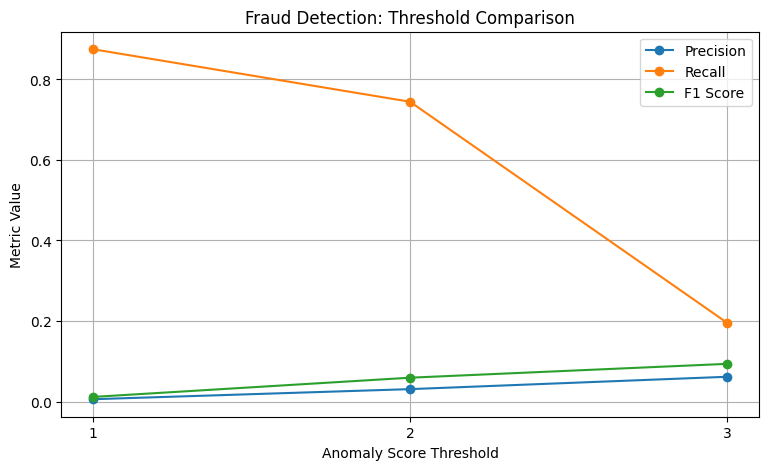

In [98]:
plt.figure(figsize=(9, 5))

plt.plot(
    results_df['Threshold'],
    results_df['Precision'],
    marker='o',
    label='Precision'
)

plt.plot(
    results_df['Threshold'],
    results_df['Recall'],
    marker='o',
    label='Recall'
)

plt.plot(
    results_df['Threshold'],
    results_df['F1 Score'],
    marker='o',
    label='F1 Score'
)

plt.xlabel('Anomaly Score Threshold')
plt.ylabel('Metric Value')
plt.title('Fraud Detection: Threshold Comparison')

plt.xticks([1, 2, 3])
plt.legend()
plt.grid(True)

plt.show()

In [99]:
results_df['Total_Cost'] = (
    results_df['FN'] * 5000 +
    results_df['FP'] * 100
)

print(
    results_df[
        ['Threshold', 'FP', 'FN', 'Total_Cost']
    ]
)

   Threshold     FP   FN  Total_Cost
0          1  27660   23     2881000
1          2   4304   47      665400
2          3    549  148      794900


In [100]:
results_df.to_csv(
    '/content/fraud_threshold_evaluation.csv',
    index=False
)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!


In [101]:
# Total transactions
total_transactions = len(df)

# Total fraud transactions
total_fraud = df['is_fraud'].sum()

# Genuine transactions
total_normal = total_transactions - total_fraud

# Fraud percentage
fraud_percentage = (
    total_fraud / total_transactions
) * 100

# Average transaction amount
average_amount = df['amt'].mean()

# Maximum transaction amount
maximum_amount = df['amt'].max()

print("========== FRAUD DETECTION DASHBOARD ==========")

print("Total Transactions:", total_transactions)
print("Fraud Transactions:", total_fraud)
print("Genuine Transactions:", total_normal)

print("Fraud Percentage:", round(fraud_percentage, 4), "%")

print("Average Transaction Amount:", round(average_amount, 2))

print("Maximum Transaction Amount:", round(maximum_amount, 2))

========== FRAUD DETECTION DASHBOARD ==========
Total Transactions: 555719
Fraud Transactions: 2145
Genuine Transactions: 553574
Fraud Percentage: 0.386 %
Average Transaction Amount: 69.39
Maximum Transaction Amount: 22768.11


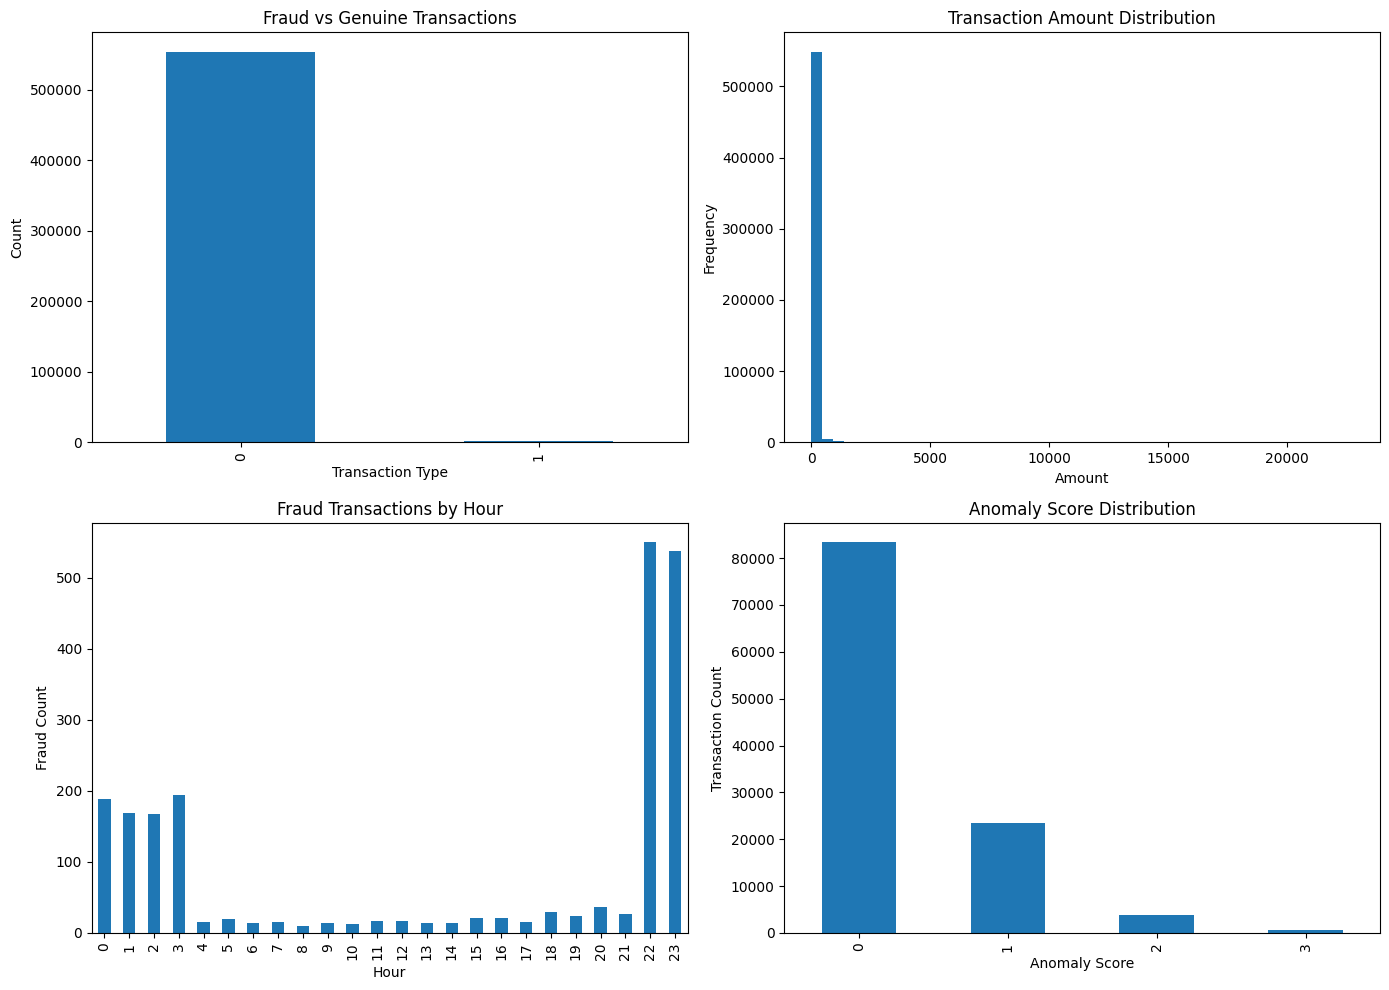

In [102]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Chart 1: Fraud vs genuine transactions
df['is_fraud'].value_counts().plot(
    kind='bar',
    ax=axes[0, 0]
)

axes[0, 0].set_title('Fraud vs Genuine Transactions')
axes[0, 0].set_xlabel('Transaction Type')
axes[0, 0].set_ylabel('Count')

# Chart 2: Transaction amount distribution
axes[0, 1].hist(
    df['amt'],
    bins=50
)

axes[0, 1].set_title('Transaction Amount Distribution')
axes[0, 1].set_xlabel('Amount')
axes[0, 1].set_ylabel('Frequency')

# Chart 3: Fraud by hour
fraud_by_hour = (
    df[df['is_fraud'] == 1]
    .groupby('transaction_hour')
    .size()
)

fraud_by_hour.plot(
    kind='bar',
    ax=axes[1, 0]
)

axes[1, 0].set_title('Fraud Transactions by Hour')
axes[1, 0].set_xlabel('Hour')
axes[1, 0].set_ylabel('Fraud Count')

# Chart 4: Anomaly score distribution
valid_eval['anomaly_score'].value_counts().sort_index().plot(
    kind='bar',
    ax=axes[1, 1]
)

axes[1, 1].set_title('Anomaly Score Distribution')
axes[1, 1].set_xlabel('Anomaly Score')
axes[1, 1].set_ylabel('Transaction Count')

plt.tight_layout()
plt.show()

In [103]:
findings = []

# Finding 1: Dataset size
findings.append(
    f"The dataset contains {len(df):,} transactions."
)

# Finding 2: Fraud percentage
findings.append(
    f"Fraud represents {df['is_fraud'].mean() * 100:.4f}% of all transactions."
)

# Finding 3: Average fraud amount
fraud_avg = df.loc[df['is_fraud'] == 1, 'amt'].mean()

findings.append(
    f"The average fraudulent transaction amount is {fraud_avg:.2f}."
)

# Finding 4: Average genuine amount
normal_avg = df.loc[df['is_fraud'] == 0, 'amt'].mean()

findings.append(
    f"The average genuine transaction amount is {normal_avg:.2f}."
)

# Finding 5: Most common fraud category
fraud_category = (
    df[df['is_fraud'] == 1]['category']
    .value_counts()
    .idxmax()
)

findings.append(
    f"The category with the highest fraud transaction count is {fraud_category}."
)

# Finding 6: Hour with most fraud transactions
fraud_hour = (
    df[df['is_fraud'] == 1]['transaction_hour']
    .value_counts()
    .idxmax()
)

findings.append(
    f"The highest fraud transaction count occurs at hour {fraud_hour}:00."
)

# Finding 7: Highest fraud-rate category
highest_rate_category = category_analysis['fraud_rate'].idxmax()

findings.append(
    f"The category with the highest observed fraud rate is {highest_rate_category}."
)

# Finding 8: Threshold with the lowest hypothetical cost
best_threshold = results_df.loc[
    results_df['Total_Cost'].idxmin(),
    'Threshold'
]

findings.append(
    f"Among the three tested thresholds, threshold {best_threshold} has the lowest illustrative cost."
)

for i, finding in enumerate(findings, start=1):
    print(f"{i}. {finding}")

1. The dataset contains 555,719 transactions.
2. Fraud represents 0.3860% of all transactions.
3. The average fraudulent transaction amount is 528.36.
4. The average genuine transaction amount is 67.61.
5. The category with the highest fraud transaction count is shopping_net.
6. The highest fraud transaction count occurs at hour 22:00.
7. The category with the highest observed fraud rate is shopping_net.
8. Among the three tested thresholds, threshold 2 has the lowest illustrative cost.


In [104]:
final_suspicious = valid_eval[
    valid_eval['anomaly_score'] >= 2
].copy()

print("Suspicious transactions:", len(final_suspicious))

final_suspicious[
    [
        'trans_date_trans_time',
        'merchant',
        'category',
        'amt',
        'anomaly_score',
        'is_fraud'
    ]
].head(10)

Suspicious transactions: 4441


,trans_date_trans_time,merchant,category,amt,anomaly_score,is_fraud
444631,2020-12-07 13:45:00,fraud_Kemmer-Buckridge,misc_pos,262.35,2,0
444674,2020-12-07 13:55:00,fraud_Herman Inc,misc_pos,692.69,2,0
444691,2020-12-07 13:57:00,fraud_Macejkovic-Lesch,shopping_pos,604.97,2,0
444704,2020-12-07 13:59:00,"fraud_Goyette, Howell and Collier",shopping_pos,653.89,2,0
444725,2020-12-07 14:03:00,fraud_Dooley Inc,shopping_pos,367.51,2,0
444734,2020-12-07 14:04:00,fraud_Schmeler-Howe,personal_care,333.76,2,0
444739,2020-12-07 14:05:00,fraud_Hudson-Grady,shopping_pos,599.83,2,0
444755,2020-12-07 14:08:00,fraud_Bauch-Blanda,entertainment,303.69,2,0
444814,2020-12-07 14:18:00,"fraud_Champlin, Rolfson and Connelly",travel,1883.60,2,0
444927,2020-12-07 14:36:00,"fraud_Hahn, Douglas and Schowalter",travel,484.22,2,0


In [105]:
final_suspicious.to_csv(
    '/content/final_suspicious_transactions.csv',
    index=False
)

print("Final suspicious transactions saved!")

Final suspicious transactions saved!


In [106]:
import os

os.makedirs('/content/Fraud_Detection_Project', exist_ok=True)

# Save important files
df.to_csv(
    '/content/Fraud_Detection_Project/audited_transactions.csv',
    index=False
)

customer_summary.to_csv(
    '/content/Fraud_Detection_Project/customer_summary.csv',
    index=False
)

results_df.to_csv(
    '/content/Fraud_Detection_Project/threshold_evaluation.csv',
    index=False
)

final_suspicious.to_csv(
    '/content/Fraud_Detection_Project/suspicious_transactions.csv',
    index=False
)

print("Project files saved successfully!")


Project files saved successfully!
